In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model, Model
from tensorflow.keras.layers import GlobalAveragePooling2D
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay)

c:\Users\mrpar\AppData\Local\Programs\Python\Python310\lib\site-packages\google\api_core\_python_version_support.py:223: FutureWarning: You are using a non-supported Python version (3.10.11). Google will not post any further updates to google.api_core supporting this Python version. Please upgrade to the latest Python version, or at least Python 3.11, and then update google.api_core.
  warnings.warn(message, FutureWarning)


In [3]:
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras.applications.resnet50 import preprocess_input
model = load_model(
    "resnet50_expanded_dataset_finetuned.keras",
    custom_objects={
        "preprocess_input": preprocess_input
    },
    compile=False,
    safe_mode=False
)
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_1 (Lambda)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │         6,147 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,593,859 (90.00 MB)

 Trainable params: 14,456,323 (55.15 MB)

 Non-trainable params: 9,137,536 (34.86 MB)

In [4]:
gap_layer = next(
    layer for layer in model.layers
    if isinstance(layer, GlobalAveragePooling2D)
)
feature_extractor = Model(
    inputs=model.inputs,
    outputs=gap_layer.output
)
feature_extractor.summary()

Model: "functional_15"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_1 (Lambda)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,587,712 (89.98 MB)

 Trainable params: 14,450,176 (55.12 MB)

 Non-trainable params: 9,137,536 (34.86 MB)

In [5]:
DATASET_PATH = r"C:\Users\mrpar\Downloads\Telegram Desktop\survillenceimagesexpanded"

IMG_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 123

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.3,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

val_test_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.3,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

class_names = train_ds.class_names

val_size = int(0.5 * len(val_test_ds))

val_ds = val_test_ds.take(val_size)
test_ds = val_test_ds.skip(val_size)

print("Classes:", class_names)
print("Training batches:", len(train_ds))
print("Validation batches:", len(val_ds))
print("Testing batches:", len(test_ds))

Found 1049 files belonging to 3 classes.
Using 735 files for training.
Found 1049 files belonging to 3 classes.
Using 314 files for validation.
Classes: ['dangerimagesexpanded', 'isolatedimagesexpanded', 'safeimagesexpanded']
Training batches: 46
Validation batches: 10
Testing batches: 10


In [6]:
def extract_features(dataset, feature_extractor):
    features = []
    labels = []
    for images, batch_labels in dataset:
        batch_features = feature_extractor(
            images,
            training=False
        )
        features.append(batch_features.numpy())
        labels.append(batch_labels.numpy())
    X = np.concatenate(features, axis=0)
    y = np.concatenate(labels, axis=0)
    return X, y

In [7]:
X_train_features, y_train = extract_features(train_ds, feature_extractor)
print("Training features:", X_train_features.shape)
print("Training labels:", y_train.shape)

Training features: (735, 2048)
Training labels: (735,)


In [8]:
X_val_features, y_val = extract_features(val_ds, feature_extractor)
print("Validation features:", X_val_features.shape)
print("Validation labels:", y_val.shape)

Validation features: (160, 2048)
Validation labels: (160,)


In [9]:
X_test_features, y_test = extract_features(test_ds, feature_extractor)
print("Testing features:", X_test_features.shape)
print("Testing labels:", y_test.shape)

Testing features: (154, 2048)
Testing labels: (154,)


In [10]:
xgb_model = XGBClassifier(n_estimators=300, max_depth=5,learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, objective="multi:softprob",
    num_class=3, eval_metric="mlogloss", random_state=123, tree_method="hist", n_jobs=-1)
xgb_model.fit(X_train_features, y_train, eval_set=[(X_val_features, y_val)], verbose=True)
print("XGBoost training completed!")

[0]	validation_0-mlogloss:1.10244
[1]	validation_0-mlogloss:1.07175
[2]	validation_0-mlogloss:1.04072
[3]	validation_0-mlogloss:1.01300
[4]	validation_0-mlogloss:0.98848
[5]	validation_0-mlogloss:0.96293
[6]	validation_0-mlogloss:0.93595
[7]	validation_0-mlogloss:0.91442
[8]	validation_0-mlogloss:0.89282
[9]	validation_0-mlogloss:0.87203
[10]	validation_0-mlogloss:0.85600
[11]	validation_0-mlogloss:0.84005
[12]	validation_0-mlogloss:0.82481
[13]	validation_0-mlogloss:0.80899
[14]	validation_0-mlogloss:0.79479
[15]	validation_0-mlogloss:0.78259
[16]	validation_0-mlogloss:0.76911
[17]	validation_0-mlogloss:0.75331
[18]	validation_0-mlogloss:0.73890
[19]	validation_0-mlogloss:0.72484
[20]	validation_0-mlogloss:0.71543
[21]	validation_0-mlogloss:0.70701
[22]	validation_0-mlogloss:0.69737
[23]	validation_0-mlogloss:0.68723
[24]	validation_0-mlogloss:0.67743
[25]	validation_0-mlogloss:0.67001
[26]	validation_0-mlogloss:0.66115
[27]	validation_0-mlogloss:0.65306
[28]	validation_0-mlogloss:0.6

In [11]:
y_pred = xgb_model.predict(X_test_features)
accuracy = accuracy_score(y_test, y_pred)
print("ResNet50 + XGBoost Test Accuracy:", round(accuracy * 100, 2), "%")

ResNet50 + XGBoost Test Accuracy: 88.31 %


In [12]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred, labels=[0, 1, 2], target_names=class_names, zero_division=0))

                        precision    recall  f1-score   support

  dangerimagesexpanded       0.86      0.91      0.89        56
isolatedimagesexpanded       0.94      0.90      0.92        52
    safeimagesexpanded       0.84      0.83      0.84        46

              accuracy                           0.88       154
             macro avg       0.88      0.88      0.88       154
          weighted avg       0.88      0.88      0.88       154



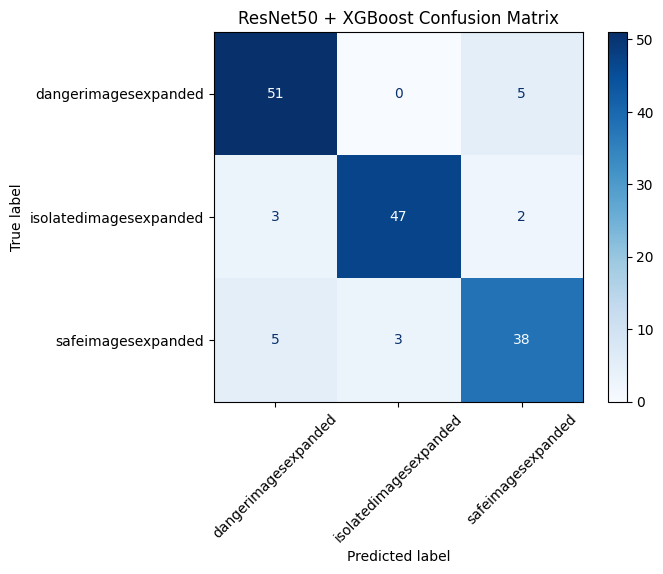

In [13]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("ResNet50 + XGBoost Confusion Matrix")
plt.show()

In [14]:
xgb_model.save_model("resnet50_xgboost_classifier.json")
print("XGBoost model saved successfully!")

XGBoost model saved successfully!
